In [152]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge

In [153]:
## 다중회귀 - 특성이 여러 개일 때
df = pd.read_csv('data/perch_full.csv')
df.head(3)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43


In [154]:
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [155]:
# 학습데이터 / 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [156]:
# 특성값 추가 # PolynomialFeatures
poly = PolynomialFeatures(degree=17,include_bias=False)  #include_bias=False 학습의미없는 데이터 1를 생략

## degree를 늘린다고 정확도가 높아지는 건 아니다**** 과대적합

# test
# poly.fit([[2,3]])                       #훈련
# train_poly = poly.transform([[2,3]])    #변형
# train_poly                              

In [157]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

train_data.shape        #결과값 (42,3)
train_poly.shape        #결과값 (42,9)

(42, 1139)

In [158]:
train_poly[:2]

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        4.62412954e+08, 2.73489374e+08, 1.61752470e+08],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        5.45625431e+09, 3.26632911e+09, 1.95535348e+09]], shape=(2, 1139))

In [159]:
print(poly.get_feature_names_out())

['length' ' height' ' width' ... ' height^2  width^15' ' height  width^16'
 ' width^17']


In [160]:
# 1차원
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('무게 예측: ', predict)

score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

무게 예측:  [-322.78309496   52.96101903  329.77783424  171.46884473  149.65836217
  789.639144    383.68482432  250.05247716  813.2470793   126.13660027
  980.20626415  -33.35965799  357.76466578  421.8675313 ]
정확도:95.59326821885706%, 87.96419177546366%


In [161]:
# 2차원
lr = LinearRegression()
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('무게 예측: ', predict)

score = lr.score(train_poly, train_label)
score2 = lr.score(test_poly, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

무게 예측:  [ 162.77113101  162.79491673  160.14689041  163.01538667  162.50522395
  629.86743389  128.12669465  163.20251711  838.8168149   162.82974185
 -754.35372289  162.77298931  161.68679393  178.02117583]
정확도:93.78712937807022%, -129.88231241629197%


# 규제 / 정규화 진행

In [166]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)


In [173]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list:

    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled, train_label)
    score2 = ridge.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료')

완료


In [174]:
# # 다중회귀
# score = ridge.score(train_scaled, train_label)
# score2 = ridge.score(test_scaled, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

정확도:98.46824250611482%, 98.18916802306978%


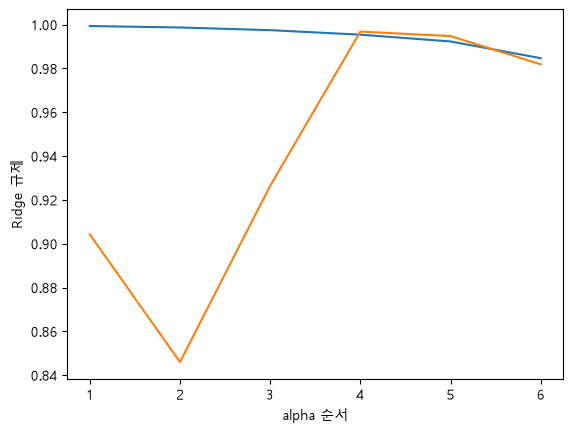

In [176]:
# 그래프 그리기
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('Ridge 규제')
plt.show()